# 02 · What lies behind an unsupported label?

**Reader goal:** recognise concrete diagnostic patterns while separating generated
content from evidence extraction, candidate selection and automated judgement.

**Reading route:** label composition → task prevalence → candidate and provenance
limits → six traceable cases → a source-layout check that challenges a label.

The six labels partition unsupported DCs in the frozen BACE pipeline. They are
**automated diagnostic categories**, not verified error classes. In particular,
a statement that a metric is not disclosed is not equivalent to fabricated data.

**How to read this notebook.** Each figure begins with a specific question. Its
caption explains the encodings and analysis scope; the following paragraphs
describe the observed pattern, its interpretation, and the remaining limits.
For multi-panel figures, read the individual panels and then their joint meaning.
“Middle half” means the 25th–75th percentiles. In an empirical cumulative
distribution (ECDF), the vertical coordinate is the proportion at or below the
horizontal value; a steep section marks a concentration of observations.
All of this text remains visible when code is hidden.

In [1]:
from pathlib import Path
import sys
analysis_dir = Path.cwd()
if not (analysis_dir / 'analysis_data.py').exists():
    analysis_dir = analysis_dir / 'BACE' / 'analysis'
assert (analysis_dir / 'analysis_data.py').exists(), 'Run from the project root or analysis directory.'
sys.path.insert(0, str(analysis_dir))
sys.dont_write_bytecode = True
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from analysis_data import (load_snapshot, company_bootstrap, case_material, read, rows,
                           save_json, sha, HERE, BACE, ROOT, OUT, CACHE, SEED, METHODS, TASKS, LABELS)
from figure_style import (canvas, save_figure, quote_figure, ecdf, note,
                          BLUE, GREEN, ORANGE, GREY, INK, CMAP,
                          METHOD_COLORS, TYPE_COLORS, LABEL_NAMES, LABEL_COLORS)
tables = load_snapshot()
metrics = tables['metrics']
common = metrics.loc[metrics.bace_complete & metrics.ragchecker_complete & metrics.ragas_complete].copy()
bace = metrics.loc[metrics.bace_complete].copy()
claims = tables['claims']
sample = read(CACHE / 'sample.json')
execution = read(CACHE / 'execution.json')
note(f"**Snapshot:** {len(metrics):,} planned disclosures from {metrics.company_id.nunique()} companies; "
     f"{len(bace):,} complete BACE results and {len(common):,} common completed cases. "
     f"Run status: `{execution['status']}`. All results are automated; no human accuracy benchmark is supplied.")

**Snapshot:** 1,800 planned disclosures from 30 companies; 1,798 complete BACE results and 1,798 common completed cases. Run status: `incomplete`. All results are automated; no human accuracy benchmark is supplied.

**Statistical scope.** The primary unit of presentation is a disclosure (company × year × task).
Repeated disclosures and extracted claims from the same company are dependent.
Where shown, 95% percentile intervals use 2,000 company-cluster bootstrap draws
(seed 20260921), resampling companies with replacement and retaining all their
observed disclosures. These are empirical, unweighted sample summaries, not
design-adjusted population estimates. They do not capture generation/judge
randomness or uncertainty due to the two missing BACE results. Subgroup comparisons
are descriptive; no hypothesis tests, significance stars or causal claims are made.

## 1. Which labels dominate, and how often do they occur?

The same count answers different questions depending on its denominator:
all DCs, unsupported DCs, or disclosures containing at least one such label.
All three are retained below.

<a id="reading-02_label_composition"></a>

**Figure question · 02 label composition.** Which automatic labels account for most unsupported DCs, and are they confined to a few disclosures?

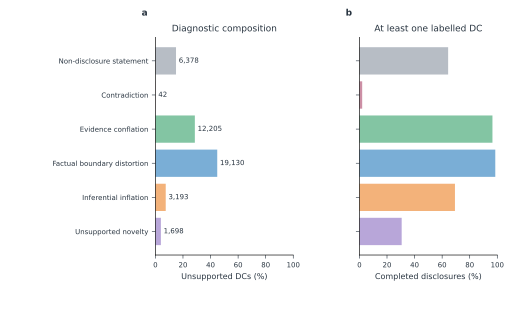

**Read the figure:** panel a partitions all unsupported DCs; panel b measures label presence in a disclosure, so its bars can sum above 100%. All-DC proportions and exact counts accompany the figure. Counts are descriptive; claims within companies are dependent.

[PDF](outputs/figures/02/02_label_composition.pdf) · [SVG](outputs/figures/02/02_label_composition.svg) · [PNG](outputs/figures/02/02_label_composition.png) · [Source data: data](outputs/figures/02/02_label_composition__data.csv)

**Pattern and evidence.** Panel a partitions 42,646 unsupported DCs and is dominated by boundary distortion (44.9%) and conflation (28.6%); together they comprise 73.5% of unsupported DCs. Contradiction is a very small bar: 42 claims (0.10% of unsupported DCs). Panel b uses 1,798 completed disclosures and shows that the two dominant labels also occur broadly, in 98.6% and 96.5% of completed disclosures. Non-disclosure statements are 15.0% of unsupported DCs but appear in 64.3% of disclosures.

**Interpretation.** The main diagnostic burden is distributed across many disclosures, rather than being generated by only a few large claim inventories. The differing bar lengths across panels show why frequency per claim and prevalence per disclosure answer different questions. A category can be a modest share of DCs while appearing in most disclosures.

**Limits and alternative readings.** Panel a categories are mutually exclusive for each DC; panel b categories can co-occur within one disclosure. These are frequencies of automated labels, not validated frequencies of error. The rare contradiction category is especially unsuitable for broad conclusions from one illustrative case.

In [2]:
unsupported=claims[claims.label.isin(LABELS)].copy()
composition=pd.DataFrame([{'label':label,'count':int((unsupported.label==label).sum()),
                          'disclosures':unsupported.loc[unsupported.label==label,'generation_case_id'].nunique()} for label in LABELS])
composition['percent_all_dc']=100*composition['count']/len(claims)
composition['percent_unsupported']=100*composition['count']/len(unsupported)
composition['percent_disclosures']=100*composition.disclosures/len(bace)
fig,axs=canvas(height=110,cols=2,left=.30,right=.96,bottom=.18,top=.88,wspace=.48)
y=np.arange(len(composition))
axs[0].barh(y,composition.percent_unsupported,color=[LABEL_COLORS[x] for x in LABELS])
for i,r in enumerate(composition.itertuples()): axs[0].text(r.percent_unsupported+2,i,f'{r.count:,}',va='center',fontsize=7)
axs[1].barh(y,composition.percent_disclosures,color=[LABEL_COLORS[x] for x in LABELS])
for ax in axs:
    ax.invert_yaxis();ax.set_xlim(0,100);ax.set_yticks(y,[LABEL_NAMES[x] for x in LABELS] if ax is axs[0] else ['']*len(y))
axs[0].set_xlabel('Unsupported DCs (%)');axs[1].set_xlabel('Completed disclosures (%)')
axs[0].set_title('Diagnostic composition');axs[1].set_title('At least one labelled DC')
save_figure(fig,'02_label_composition',composition,
    '**Read the figure:** panel a partitions all unsupported DCs; panel b measures label presence in a disclosure, so its bars can sum above 100%. '
    'All-DC proportions and exact counts accompany the figure. Counts are descriptive; claims within companies are dependent.')
top=composition.sort_values('count',ascending=False).iloc[0]

## 2. Do the same patterns appear across tasks?

Task-level proportions use **all DCs within each task** as the denominator.
This avoids making a task with very few unsupported claims look equally burdened
just because its unsupported subset has a distinctive composition.

<a id="reading-02_task_patterns"></a>

**Figure question · 02 task patterns.** Does the overall diagnostic composition recur in every task, or do some tasks show distinctive concentrations?

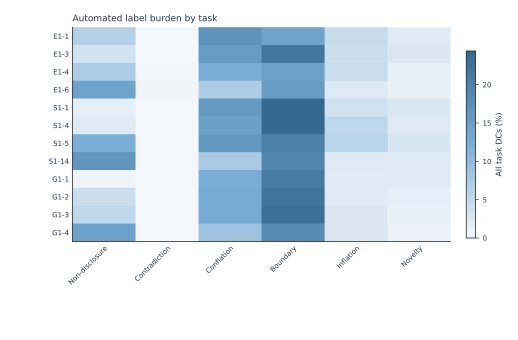

**Read the figure:** each cell is the percentage of all DCs in that task assigned the column label; all tasks and all six labels are shown. No clustering, row scaling, significance test or post-hoc task selection is used. Source data include each denominator.

[PDF](outputs/figures/02/02_task_patterns.pdf) · [SVG](outputs/figures/02/02_task_patterns.svg) · [PNG](outputs/figures/02/02_task_patterns.png) · [Source data: data](outputs/figures/02/02_task_patterns__data.csv)

**Pattern and evidence.** Boundary distortion is the largest of the six label shares in 11/12 task rows, ranging from 13.9% to 24.4% of all task DCs. Non-disclosure forms local dark cells: S1-14 reaches 16.4%, whereas G1-1 is 0.42%. The contradiction column remains almost white (maximum 0.23%). Summing the six shares gives an unsupported claim fraction from 37.7% (G1-1) to 56.7% (S1-5).

**Interpretation.** The broad boundary column supports a cross-task inspection priority, while the non-disclosure hotspots suggest that the treatment of missing target-year metrics matters unevenly across tasks. The nearly empty contradiction column reflects its rarity in this output taxonomy, not absence of every possible factual problem.

**Limits and alternative readings.** Colours share a common percentage scale and use all DCs within each task, without row normalisation. These pooled fractions give larger claim inventories more weight, so they need not equal one minus notebook 01’s macro support. The grid cannot separate source insufficiency, generated assertions, segmentation or diagnostic behaviour as causes.

In [3]:
joined=claims.merge(bace[['generation_case_id','task']],on='generation_case_id',validate='many_to_one')
counts=pd.crosstab(joined.task,joined.label).reindex(index=TASKS,columns=LABELS,fill_value=0)
denominators=joined.groupby('task').size().reindex(TASKS)
rates=counts.div(denominators,axis=0)*100
fig,(ax,)=canvas(height=120,left=.14,right=.87,bottom=.29,top=.92)
im=ax.imshow(rates,cmap=CMAP,vmin=0,vmax=max(1,rates.to_numpy().max()),aspect='auto')
ax.set_yticks(range(len(TASKS)),TASKS);ax.set_xticks(range(len(LABELS)),['Non-disclosure','Contradiction','Conflation','Boundary','Inflation','Novelty'],rotation=45,ha='right',rotation_mode='anchor')
ax.tick_params(length=0);ax.set_title('Automated label burden by task',loc='left')
cbax=fig.add_axes([.90,.30,.018,.55]);cbax.set_label('<colorbar>');fig.colorbar(im,cax=cbax,label='All task DCs (%)')
source=rates.reset_index().melt(id_vars='task',var_name='label',value_name='percent_all_dc').merge(denominators.rename('all_dc'),on='task')
save_figure(fig,'02_task_patterns',source,
    '**Read the figure:** each cell is the percentage of all DCs in that task assigned the column label; all tasks and all six labels are shown. '
    'No clustering, row scaling, significance test or post-hoc task selection is used. Source data include each denominator.',axes=[ax])

## 3. Which parts of the pipeline require scrutiny?

A judgement can be affected by what was extracted from the evidence, which ECs
were offered as candidates, and how the judge read those ECs. An empty candidate
set is informative about this pipeline path; it does not prove that the full
visible source contained no relevant information. Literal quote localisation is
also only a provenance check, not a semantic fidelity test.

<a id="reading-02_pipeline_checks"></a>

**Figure question · 02 pipeline checks.** Before reading cases, do candidate availability and quote localisation reveal different diagnostic paths?

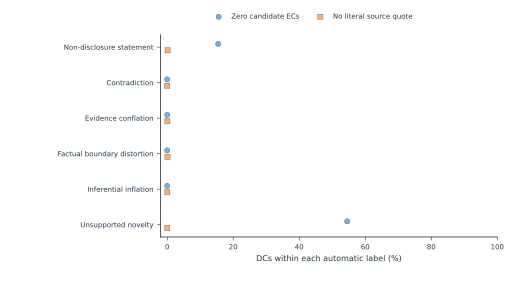

**Read the figure:** each point is a label-specific proportion among unsupported DCs. A literal quote must occur contiguously in the generated response. **Boundary:** noncontiguous table quotations can fail that check without being invented; neither indicator is an error-rate estimate.

[PDF](outputs/figures/02/02_pipeline_checks.pdf) · [SVG](outputs/figures/02/02_pipeline_checks.svg) · [PNG](outputs/figures/02/02_pipeline_checks.png) · [Source data: data](outputs/figures/02/02_pipeline_checks__data.csv)

**Pattern and evidence.** The blue markers separate into two nonzero rows and four at zero. Unsupported novelty has 926/1698 DCs without candidates (54.5%), compared with 985/6378 non-disclosure DCs (15.4%). All orange markers sit near zero: only 33/42,646 unsupported DCs lack a contiguous generated-text quote; the largest within-label fraction is 0.14%.

**Interpretation.** Candidate absence is concentrated in particular categories, whereas literal quote localisation succeeds almost everywhere. This makes candidate/extraction inspection relevant to novelty cases, but the near-zero orange markers only say that a quoted span can be found in the generated response. They do not validate its meaning or its evidence support.

**Limits and alternative readings.** The 0–100% axis visually compresses tiny quote-localisation differences. A candidate can exist and still be irrelevant, and an empty candidate list can result from information loss earlier in the pipeline. The label and candidate route belong to the same automated process, so their association is not independent validation.

In [4]:
checks=unsupported.groupby('label').agg(claims=('dc_id','size'),zero_candidates=('candidate_count',lambda x:int((x==0).sum())),
                                       no_exact_quote=('exact_quote_count',lambda x:int((x==0).sum()))).reindex(LABELS)
checks['zero_candidate_percent']=100*checks.zero_candidates/checks.claims
checks['no_exact_quote_percent']=100*checks.no_exact_quote/checks.claims
fig,(ax,)=canvas(height=102,left=.31,bottom=.18)
for j,(column,label,color,marker) in enumerate([('zero_candidate_percent','Zero candidate ECs',BLUE,'o'),('no_exact_quote_percent','No literal source quote',ORANGE,'s')]):
    ax.scatter(checks[column],np.arange(len(checks))+(j-.5)*.18,color=color,label=label,marker=marker,s=28,edgecolor=INK,linewidth=.3)
ax.set_yticks(range(len(checks)),[LABEL_NAMES[x] for x in checks.index]);ax.invert_yaxis();ax.set_xlim(0,100)
ax.set_xlim(-2,100);ax.set_xticks([0,20,40,60,80,100])
ax.set_xlabel('DCs within each automatic label (%)');ax.legend(loc='lower center',bbox_to_anchor=(.45,1.04),ncols=2)
save_figure(fig,'02_pipeline_checks',checks.reset_index(),
    '**Read the figure:** each point is a label-specific proportion among unsupported DCs. A literal quote must occur contiguously in the generated response. '
    '**Boundary:** noncontiguous table quotations can fail that check without being invented; neither indicator is an error-rate estimate.')

## 4. Six real cases: what changed between source and claim?

**Selection rule (fixed at the initial analysis snapshot):** for each label, sort all DCs with at least one literal
source quote by case and DC identifier; take one reproducible random example
(seed 20260921 plus the label index). This excludes unlocalised quotations only
from the illustrative sample; their counts remain above. No replacement is made
when the selected case challenges the automatic label. Selected IDs and original pool sizes are retained in a versioned manifest, so later completion of missing cases does not silently change these readings.

Each plate shows a verified generated excerpt, the extracted DC, a relevant
visible evidence excerpt and the unedited automatic rationale. The complete
visible evidence, candidates, ECs and generated text are exported in the case
bundle. The analyst's reading underneath is qualitative source inspection, not
blinded human adjudication or a population accuracy estimate.

<a id="reading-02_example_non_disclosure_statement"></a>

**Figure question · 02 example non disclosure statement.** Why can an explicitly cautious statement about missing data receive an unsupported label?

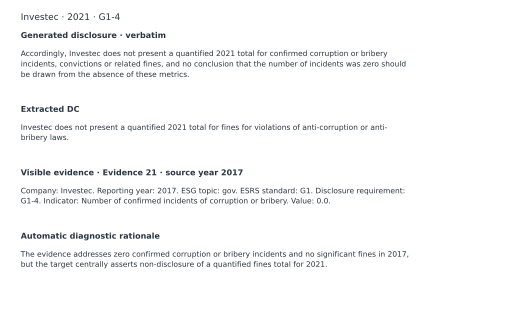

**Automatic label: Non-disclosure statement.** 6,369 localisable DCs were eligible for this illustrative draw. The evidence excerpt begins at character 0 and ends at 184. [Full case and source references](outputs/examples/02_non_disclosure_statement.json).

[PDF](outputs/figures/02/02_example_non_disclosure_statement.pdf) · [SVG](outputs/figures/02/02_example_non_disclosure_statement.svg) · [PNG](outputs/figures/02/02_example_non_disclosure_statement.png) · [Source data: data](outputs/figures/02/02_example_non_disclosure_statement__data.csv)

**Pattern and evidence.** The generated sentence withholds a quantified 2021 total and explicitly rejects treating absence as zero. The extracted DC isolates fines in 2021, whereas the displayed CSV card records zero confirmed corruption or bribery incidents in 2017. Both the year and the measure differ: incidents are not fines.

**Interpretation.** Reading the four blocks together reveals a statement about a reporting gap, not a fabricated numerical total. The older zero-incident metric cannot settle whether a 2021 fines total was supplied. This is why the category must remain distinguishable from an affirmative unsupported factual assertion.

**Limits and alternative readings.** A single card cannot prove that a metric is absent from all company publications, and this case does not establish company withholding. The label describes the frozen evidence-bound evaluation; its inclusion in the main denominator is a measurement choice examined in notebook 01.

<a id="reading-02_example_contradiction"></a>

**Figure question · 02 example contradiction.** Is the ASML contradiction between the generated claim and the source, or between two readings of extracted text?

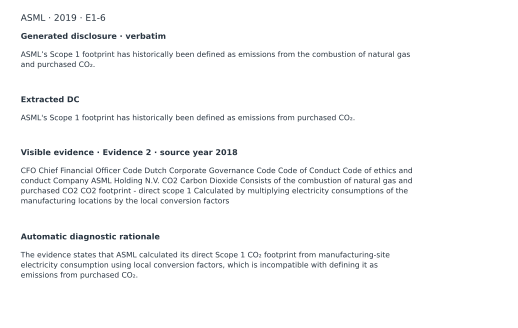

**Automatic label: Contradiction.** 42 localisable DCs were eligible for this illustrative draw. The evidence excerpt begins at character 0 and ends at 357. [Full case and source references](outputs/examples/02_contradiction.json).

[PDF](outputs/figures/02/02_example_contradiction.pdf) · [SVG](outputs/figures/02/02_example_contradiction.svg) · [PNG](outputs/figures/02/02_example_contradiction.png) · [Source data: data](outputs/figures/02/02_example_contradiction__data.csv)

**Pattern and evidence.** The top block says historical Scope 1 includes natural gas and purchased CO₂; the DC retains the purchased-CO₂ component. The source block runs glossary terms and definitions together. The automatic rationale then attributes electricity-conversion factors to Scope 1. The apparent conflict turns on which glossary label belongs to which definition.

**Interpretation.** The plate exposes a source-association question that a flat text reading cannot reliably resolve. The original-page crop later in this notebook resolves it in favour of the gas/purchased-CO₂ Scope 1 row. Accordingly, this example challenges the automatic contradiction rationale rather than supplying a clean generation error.

**Limits and alternative readings.** The original layout must be checked to establish the row relationship; proximity in the flattened text is insufficient. This one inspected case cannot estimate the error rate of the 42 automatically labelled contradiction DCs.

<a id="reading-02_example_evidence_conflation"></a>

**Figure question · 02 example evidence conflation.** What relationship does the Nestlé sentence add when it connects historical assessments to an ongoing priority?

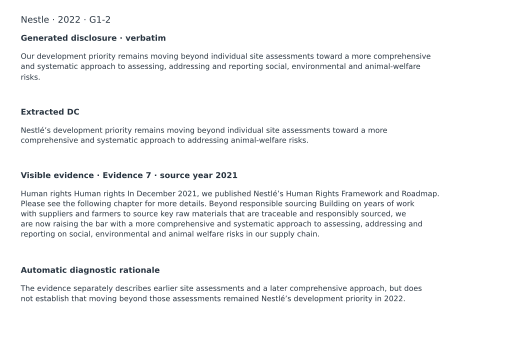

**Automatic label: Evidence conflation.** 12,199 localisable DCs were eligible for this illustrative draw. The evidence excerpt begins at character 0 and ends at 492. [Full case and source references](outputs/examples/02_evidence_conflation.json).

[PDF](outputs/figures/02/02_example_evidence_conflation.pdf) · [SVG](outputs/figures/02/02_example_evidence_conflation.svg) · [PNG](outputs/figures/02/02_example_evidence_conflation.png) · [Source data: data](outputs/figures/02/02_example_evidence_conflation__data.csv)

**Pattern and evidence.** The generated wording is “Our development priority remains moving beyond individual site assessments”. The 2021 visible source supports a “more comprehensive and systematic approach” to risks, including animal welfare. The diagnostic rationale disputes the link to earlier site assessments and its status as a continuing priority in target year 2022.

**Interpretation.** The distinctive change is relational and temporal: individually sourced ideas are joined into one continuing-development narrative. The source does contain a forward-looking expansion in approach, so this is subtler than inventing an unrelated topic. The blocks identify exactly which continuity claim needs review.

**Limits and alternative readings.** The displayed card does not include all earlier assessment material; the complete bundle contains that context. The automatic conflation label is not independently established by this plate, and one case does not quantify how often such linking is unjustified.

<a id="reading-02_example_factual_boundary_distortion"></a>

**Figure question · 02 example factual boundary distortion.** What changes when an accurately quoted historical activity is expressed as current practice?

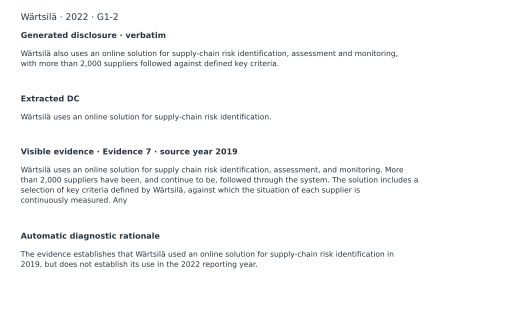

**Automatic label: Factual boundary distortion.** 19,113 localisable DCs were eligible for this illustrative draw. The evidence excerpt begins at character 0 and ends at 330. [Full case and source references](outputs/examples/02_factual_boundary_distortion.json).

[PDF](outputs/figures/02/02_example_factual_boundary_distortion.pdf) · [SVG](outputs/figures/02/02_example_factual_boundary_distortion.svg) · [PNG](outputs/figures/02/02_example_factual_boundary_distortion.png) · [Source data: data](outputs/figures/02/02_example_factual_boundary_distortion__data.csv)

**Pattern and evidence.** The visible 2019 text explicitly describes Wärtsilä’s online supply-chain risk solution and more than 2,000 suppliers. The generated sentence uses present-tense “uses” in a 2022 disclosure; the extracted DC focuses on the online solution. The rationale accepts the 2019 activity but questions whether it is established for 2022.

**Interpretation.** Most substantive wording matches; the three-year temporal carry-forward is the disputed boundary. The source’s “have been, and continue to be” wording expresses continuity at the time of the 2019 report, which explains why reuse may sound plausible while still leaving a target-year evidence gap.

**Limits and alternative readings.** Lack of a 2022 confirmation does not show that the activity stopped. Neither a historical exact match nor an automatic boundary label settles the real-world 2022 practice. This is a temporal-support illustration, not a company performance finding.

<a id="reading-02_example_inferential_inflation"></a>

**Figure question · 02 example inferential inflation.** How much of the Pennon disagreement rests on strengthening an obligation word?

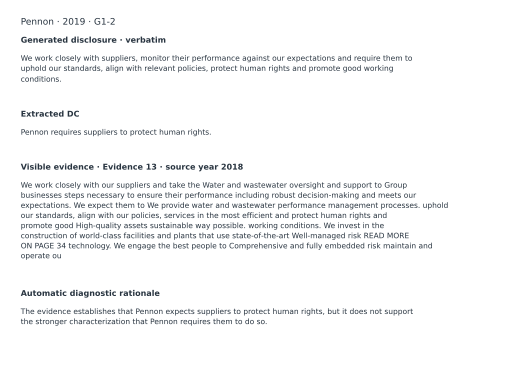

**Automatic label: Inferential inflation.** 3,192 localisable DCs were eligible for this illustrative draw. The evidence excerpt begins at character 1362 and ends at 2082. [Full case and source references](outputs/examples/02_inferential_inflation.json).

[PDF](outputs/figures/02/02_example_inferential_inflation.pdf) · [SVG](outputs/figures/02/02_example_inferential_inflation.svg) · [PNG](outputs/figures/02/02_example_inferential_inflation.png) · [Source data: data](outputs/figures/02/02_example_inferential_inflation__data.csv)

**Pattern and evidence.** The generated disclosure and DC use “require”, while the 2018 visible passage says “We expect them to” uphold standards and protect human rights. The excerpt also interleaves water-service and management text from neighbouring table columns. The rationale identifies the change from expectation to requirement.

**Interpretation.** The pattern is a shift in modal strength, rather than a new supplier or a different human-rights topic. That distinction matters because an expectation can be weaker than a binding obligation. The interleaved text also shows why the excerpt must be read as an extracted representation with layout limitations.

**Limits and alternative readings.** Other visible cards discuss supplier codes and strict procurement policies; they may affect the reading of the complete obligation. This excerpt alone does not establish the legal force of Pennon’s policy or independently verify the inflation label.

<a id="reading-02_example_unsupported_novelty"></a>

**Figure question · 02 example unsupported novelty.** Is the accident-severity indicator absent from the visible evidence, or lost before the support judgement?

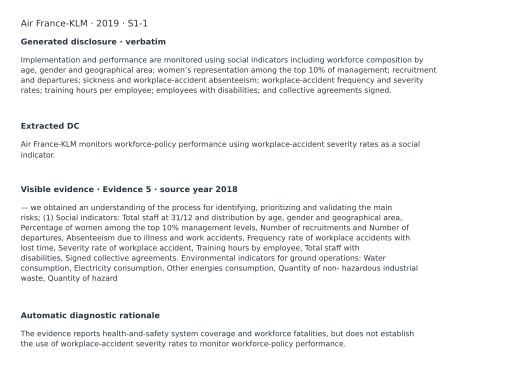

**Automatic label: Unsupported novelty.** 1,698 localisable DCs were eligible for this illustrative draw. The evidence excerpt begins at character 0 and ends at 720. [Full case and source references](outputs/examples/02_unsupported_novelty.json).

[PDF](outputs/figures/02/02_example_unsupported_novelty.pdf) · [SVG](outputs/figures/02/02_example_unsupported_novelty.svg) · [PNG](outputs/figures/02/02_example_unsupported_novelty.png) · [Source data: data](outputs/figures/02/02_example_unsupported_novelty__data.csv)

**Pattern and evidence.** The generated sentence lists workplace-accident severity among monitoring indicators. The 2018 visible card explicitly includes “Severity rate of workplace accident”, yet the rationale discusses health-and-safety coverage and fatalities without recognising that indicator. In the full bundle, the card’s three retained ECs concern risk identification, prioritisation and validation; the indicator list is omitted.

**Interpretation.** The top and source blocks share the disputed indicator, while the extracted representation does not preserve it. That supplies a concrete reason to question a simple absence-of-evidence reading of the novelty label. Inspecting only candidate ECs would miss information actually available in the prompt.

**Limits and alternative readings.** The source lists social indicators in an assurance context. Presence of the phrase does not, by itself, establish the stronger interpretation that it monitored workforce-policy performance in target year 2019. The extraction omission is observable; the full target-year support judgement still requires review.

In [5]:
# These evidence-card choices are documented qualitative readings of the fixed random examples.
card_labels=['Evidence 21','Evidence 2','Evidence 7','Evidence 7','Evidence 13','Evidence 5']
review_notes=[
 'The selected DC explicitly reports non-disclosure in 2021. A zero-incident figure for 2017 does not fill that gap. This label should not be counted as fabrication or proof that the company withheld a metric.',
 'The narrative card flattens a two-column glossary. Inspection of the original PDF below assigns purchased CO2 to direct Scope 1 and electricity conversion factors to indirect Scope 2. The automatic rationale follows a misassociated extracted EC; this is not a clean generation-contradiction example.',
 'The generated sentence links earlier site assessments to a continuing 2022 priority. The 2021 source describes a more comprehensive approach and another card describes 2010–2017 assessments. The claimed ongoing priority and the relation between those statements require judgement; the automatic conflation label is not independently established.',
 'The wording about an online solution is supported in a 2019 report, while the generated disclosure is framed as 2022. The disputed boundary is temporal carry-forward. The excerpt alone cannot establish that the company stopped using the solution.',
 'The generated sentence uses “require”; the visible 2018 source uses “expect”. The table card interleaves neighbouring columns and is reproduced without repair. Other visible cards discuss supplier codes and strict procurement policies, so the strength of the complete obligation still requires contextual review. This illustrates modal-strength judgement, not a verified error count.',
 'The full visible card explicitly lists “Severity rate of workplace accident”. Its three retained ECs concern only identifying, prioritizing and validating risks. The diagnostic candidates omit the indicator. This is evidence of an extraction omission relevant to the rationale; the stronger target-year monitoring interpretation still needs review.'
]
examples=[]
fixed_examples=read(HERE/'assets/failure_example_selection.json')
for i,label in enumerate(LABELS):
    selected=fixed_examples[i]
    assert selected['label']==label
    original_pool_size=selected['pool_size']
    pick=claims[(claims.generation_case_id==selected['case_id'])&(claims.dc_id==selected['dc_id'])].iloc[0]
    assert pick.label==label and pick.exact_quote_count>0
    material=case_material(pick.generation_case_id)
    d=next(x for x in material['dc'] if x['dc_id']==pick.dc_id)
    diag=next(x for x in material['diagnosis'] if x['dc_claim_id']==pick.dc_id)
    card=next(c for c in material['input']['prompt_evidence'] if c['prompt_label']==card_labels[i])
    quotes=[q for p in d['dc_provenance'] for q in p['source_quotes'] if q in material['response']['generated_text']]
    quote=max(quotes,key=len)
    text=card['retrieval_text']
    start=max(0,text.find('We work closely')) if label=='inferential_inflation' else 0
    excerpt=text[start:start+720]
    case_name=f"{material['input']['company_name']} · {material['input']['target_reporting_year']} · {material['input']['task_id'].split('_')[0]}"
    blocks=[('Generated disclosure · verbatim',quote),('Extracted DC',d['dc_text']),
            (f"Visible evidence · {card['prompt_label']} · source year {card['source_year']}",excerpt),
            ('Automatic diagnostic rationale',diag['rationale'])]
    (OUT/'examples').mkdir(exist_ok=True)
    save_json(OUT/'examples'/f'02_{label}.json',{'selection':{'seed':SEED+i,'pool_size':original_pool_size,'dc_id':pick.dc_id},
              'selected_card':card,'analyst_note':review_notes[i],'material':material})
    quote_figure('02_example_'+label,case_name,blocks,pd.DataFrame([{'role':a,'text':b} for a,b in blocks]),
        f"**Automatic label: {LABEL_NAMES[label]}.** {original_pool_size:,} localisable DCs were eligible for this illustrative draw. "
        f"The evidence excerpt begins at character {start} and ends at {start+len(excerpt)}. [Full case and source references](outputs/examples/02_{label}.json).")
    examples.append({'label':label,'generation_case_id':pick.generation_case_id,'dc_id':pick.dc_id,'pool_size':original_pool_size,'card':card['evidence_id']})
pd.DataFrame(examples).to_csv(OUT/'examples/02_selection.csv',index=False)

## 5. Does the original source layout support the contradiction rationale?

For the ASML example, inspect the actual report page as well as the flattened
card. The two-column glossary defines direct Scope 1 using natural gas and
purchased CO₂, and indirect Scope 2 using electricity conversion factors. The
rendering below preserves the original page layout. It is an additional source
check; the original PDF page was not separately supplied to the generator.

<a id="reading-02_asml_source_layout"></a>

**Figure question · 02 asml source layout.** Can the source page resolve the apparent Scope 1 contradiction raised in the ASML example?

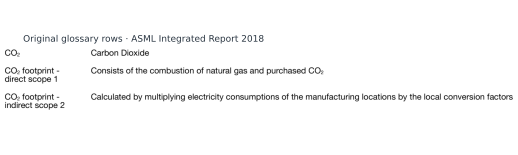

**Read the source:** ASML Integrated Report 2018, PDF page 216 (printed page 209), glossary crop. Scope 1 and Scope 2 occupy separate rows. **Observed:** the automatic contradiction rationale assigns the electricity definition to Scope 1, contrary to the original row association. This reveals a source-representation/extraction problem; it does not estimate the frequency of such problems.

[PDF](outputs/figures/02/02_asml_source_layout.pdf) · [SVG](outputs/figures/02/02_asml_source_layout.svg) · [PNG](outputs/figures/02/02_asml_source_layout.png) · [Source data: data](outputs/figures/02/02_asml_source_layout__data.csv)

**Pattern and evidence.** On PDF page 216 (printed page 209), the two glossary rows align direct Scope 1 with combustion of natural gas and purchased CO₂, and indirect Scope 2 with electricity consumption multiplied by local conversion factors. The key pattern is horizontal row association: the electricity text belongs to the second definition, although the flattened card places it after the Scope 1 label.

**Interpretation.** Preserving two-dimensional layout changes the reading. The original row association supports the historical Scope 1 wording shown earlier and contradicts the specific electricity-based premise of the automatic rationale. This is concrete evidence that source representation or EC extraction can produce a misleading diagnostic example.

**Limits and alternative readings.** This is one inspected page, and the generator received the flattened card rather than this crop. The check establishes a local association error; it does not establish the overall reliability of BACE, the frequency of PDF-layout failures, or the correctness of every statement in that disclosure.

In [6]:
import pymupdf
pdf=ROOT/'data/raw/reports_pdf/2e1f7005-6454-4596-8e28-87214e82b95e_2018_AR.pdf'
expected=read(CACHE/'source_pdfs.json')[pdf.name]
assert sha(pdf)==expected
with pymupdf.open(pdf) as document:
    page=document[215]
    pix=page.get_pixmap(matrix=pymupdf.Matrix(3,3),clip=pymupdf.Rect(50,452,538,515))
    pixels=np.frombuffer(pix.samples,dtype=np.uint8).reshape(pix.height,pix.width,pix.n)
fig,(ax,)=canvas(height=55,left=.005,right=.995,bottom=.08,top=.88)
ax.imshow(pixels);ax.axis('off');ax.set_title('Original glossary rows · ASML Integrated Report 2018',loc='left',fontsize=9,x=.04)
save_figure(fig,'02_asml_source_layout',pd.DataFrame([{'source_file':pdf.name,'sha256':expected,'pdf_page':216,'printed_page':209,'clip_points':'50,452,538,515'}]),
    '**Read the source:** ASML Integrated Report 2018, PDF page 216 (printed page 209), glossary crop. Scope 1 and Scope 2 occupy separate rows. '
    '**Observed:** the automatic contradiction rationale assigns the electricity definition to Scope 1, contrary to the original row association. This reveals a source-representation/extraction problem; it does not estimate the frequency of such problems.')

## What the reader should now be able to explain

Diagnostic composition identifies where to inspect, not a final ledger of true
errors. A difference in year, scope, relation or obligation strength can explain
an automatic label. But visible evidence can be lost during EC extraction, and
PDF reading order can change an apparent contradiction. The selected examples
therefore support both substantive interpretation and scrutiny of the evaluator.
The next notebook compares what the three evaluators measure.

## Reproducibility and interpretation boundary

Each figure is exported to `outputs/figures/` as editable PDF/SVG and 600 dpi PNG,
with its plotted source table(s), caption, and rendered QA records. The snapshot
manifest records source hashes and the verification scope. All observations are
retained unless an explicitly named cohort or case-selection rule is stated.

The source checks cover consumed artifacts and their completed-stage receipts,
shared prompt/context/response identity, and native metric arithmetic. They are
not a new audit of every raw model call or the entire extraction lineage.
Read the final audit report for figure-level visual checks and any reviewed warnings.